In [3]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

# Load trained model
final_group_model = joblib.load("../models/best_model.pkl")

# Load cleaned dataset
df = pd.read_csv(
    "../data/processed/supply_chain_cleaned.csv",
    encoding="latin1"
)

print("Model loaded successfully!")
print("Dataset shape:", df.shape)

Model loaded successfully!
Dataset shape: (180519, 51)


In [5]:
selected_features = [
    "Shipping Mode",
    "Days for shipment (scheduled)",
    "Customer Segment",
    "Market",
    "Order Region",
    "Department Name",
    "Category Name",
    "Order Item Quantity",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Order Item Product Price"
]

# Cancelled orders exclude karo
df_model = df[df["Delivery Status"] != "Shipping canceled"].copy()

# Target create karo
df_model["Target"] = (
    df_model["Delivery Status"] == "Late delivery"
).astype(int)

# Input features
X = df_model[selected_features].copy()

print("Feature shape:", X.shape)
print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (172765, 11)

Features:
['Shipping Mode', 'Days for shipment (scheduled)', 'Customer Segment', 'Market', 'Order Region', 'Department Name', 'Category Name', 'Order Item Quantity', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price']


In [6]:
# Select 1000 random samples
X_sample = X.sample(
    n=1000,
    random_state=42
)

# Get trained preprocessing pipeline
preprocessor = final_group_model.named_steps["preprocessor"]

# Transform sample data
X_sample_transformed = preprocessor.transform(X_sample)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Original sample shape:", X_sample.shape)
print("Transformed sample shape:", X_sample_transformed.shape)
print("Total transformed features:", len(feature_names))

Original sample shape: (1000, 11)
Transformed sample shape: (1000, 101)
Total transformed features: 101


In [8]:
# Extract trained XGBoost classifier
xgb_classifier = final_group_model.named_steps["classifier"]

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb_classifier)

# Calculate SHAP values
shap_values = explainer.shap_values(X_sample_transformed)

print("SHAP analysis completed!")
print("SHAP values shape:", shap_values.shape)

SHAP analysis completed!
SHAP values shape: (1000, 101)


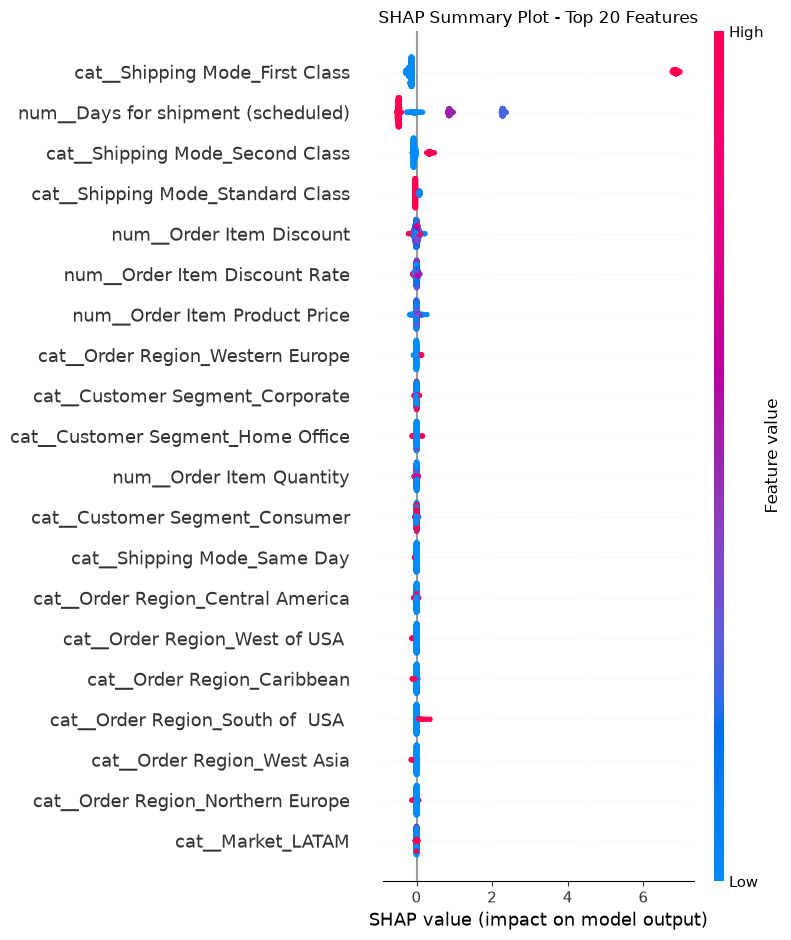

In [11]:
import numpy as np
import pandas as pd
from scipy import sparse

# Convert transformed data into dense array
if sparse.issparse(X_sample_transformed):
    X_dense = X_sample_transformed.toarray()
else:
    X_dense = np.asarray(X_sample_transformed)

# Create DataFrame with feature names
X_shap_df = pd.DataFrame(
    X_dense,
    columns=feature_names
)

# Generate improved SHAP plot
shap.summary_plot(
    shap_values,
    X_shap_df,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot - Top 20 Features")
plt.tight_layout()
plt.savefig(
    "../reports/figures/shap_summary_plot_colored.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Calculate mean absolute SHAP values
mean_shap = np.abs(shap_values).mean(axis=0)

# Create importance dataframe
shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_SHAP_Importance": mean_shap
})

# Sort by importance
shap_importance_df = shap_importance_df.sort_values(
    by="Mean_SHAP_Importance",
    ascending=False
)

# Display top 20 features
display(shap_importance_df.head(20))

,Feature,Mean_SHAP_Importance
5,cat__Shipping Mode_First Class,1.201627
0,num__Days for shipment (scheduled),0.806508
7,cat__Shipping Mode_Second Class,0.121909
8,cat__Shipping Mode_Standard Class,0.046020
2,num__Order Item Discount,0.030616
3,num__Order Item Discount Rate,0.017347
4,num__Order Item Product Price,0.014632
39,cat__Order Region_Western Europe,0.012171
10,cat__Customer Segment_Corporate,0.007436
11,cat__Customer Segment_Home Office,0.007179


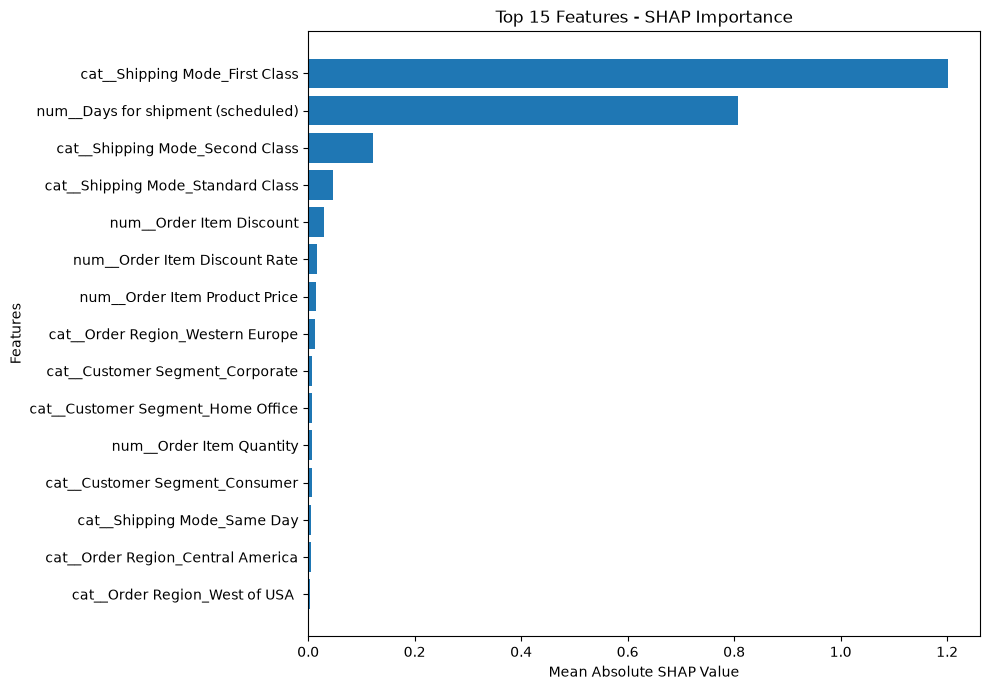

In [13]:
# visualize top 15 features

top_features = shap_importance_df.head(15).sort_values(
    by="Mean_SHAP_Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Mean_SHAP_Importance"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("Top 15 Features - SHAP Importance")

plt.tight_layout()

plt.savefig(
    "../reports/figures/shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

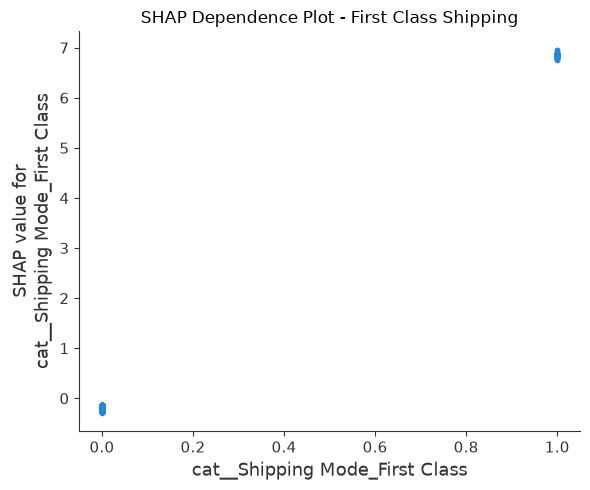

In [14]:
import shap
import matplotlib.pyplot as plt

shap.dependence_plot(
    "cat__Shipping Mode_First Class",
    shap_values,
    X_shap_df,
    interaction_index=None,
    show=False
)

plt.title("SHAP Dependence Plot - First Class Shipping")
plt.tight_layout()

plt.savefig(
    "../reports/figures/shap_first_class_dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

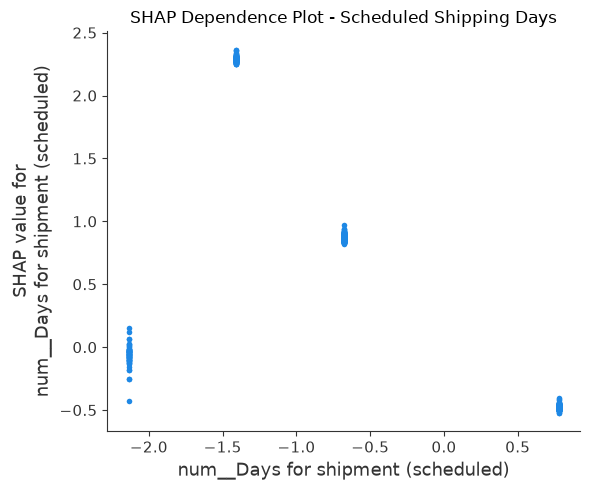

In [15]:
shap.dependence_plot(
    "num__Days for shipment (scheduled)",
    shap_values,
    X_shap_df,
    interaction_index=None,
    show=False
)

plt.title("SHAP Dependence Plot - Scheduled Shipping Days")
plt.tight_layout()

plt.savefig(
    "../reports/figures/shap_scheduled_days_dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

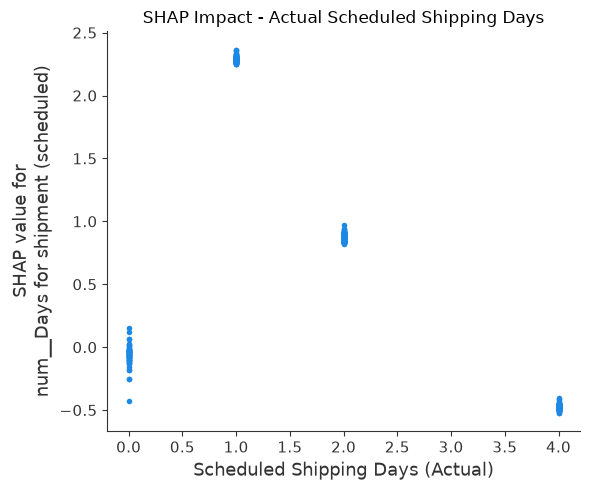

In [16]:
# Create a copy for visualization
X_shap_display = X_shap_df.copy()

# Replace standardized values with original scheduled days
X_shap_display["num__Days for shipment (scheduled)"] = (
    X_sample["Days for shipment (scheduled)"].to_numpy()
)

# Generate dependence plot
shap.dependence_plot(
    "num__Days for shipment (scheduled)",
    shap_values,
    X_shap_display,
    interaction_index=None,
    show=False
)

plt.title("SHAP Impact - Actual Scheduled Shipping Days")
plt.xlabel("Scheduled Shipping Days (Actual)")
plt.tight_layout()

plt.savefig(
    "../reports/figures/shap_actual_scheduled_days.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Numerical SHAP analysis

# Find the scheduled shipping days feature index
feature_index = list(feature_names).index(
    "num__Days for shipment (scheduled)"
)

# Get corresponding SHAP values
scheduled_days_shap = shap_values[:, feature_index]

# Create analysis dataframe
scheduled_analysis = pd.DataFrame({
    "Scheduled_Days": X_sample[
        "Days for shipment (scheduled)"
    ].to_numpy(),
    "SHAP_Value": scheduled_days_shap
})

# Group-wise analysis
scheduled_summary = (
    scheduled_analysis
    .groupby("Scheduled_Days")
    .agg(
        Sample_Count=("SHAP_Value", "count"),
        Average_SHAP=("SHAP_Value", "mean"),
        Mean_Absolute_SHAP=("SHAP_Value", lambda x: x.abs().mean())
    )
    .reset_index()
)

display(scheduled_summary.round(4))

,Scheduled_Days,Sample_Count,Average_SHAP,Mean_Absolute_SHAP
0,0,65,-0.0629,0.0776
1,1,156,2.2869,2.2869
2,2,189,0.8724,0.8724
3,4,590,-0.4743,0.4743
